### importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Getting dataset

In [6]:
df=pd.read_csv("../dataset/olist_order_items_dataset.csv")

In [7]:
df.head(3)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


In [8]:
df.shape

(112650, 7)

In [9]:
df.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

### insights
1) order_id is unique value assigned to each order.
2) order_item_id is to get no. of items in each order.
3) product_id is to identify the product in each order.
4) seller_id is the product seller.
5) shipping_limit_date is date upto which the order to be provided to the carrier.
6) price is value of individual item in order.
7) freight_value are shipping charges.

In [13]:
### total order placed
df['order_id'].nunique()

98666

In [22]:
### total products ordered
pro=df['order_id'].astype(str)+'_'+df['order_item_id'].astype(str)
len(pro)

112650

In [24]:
### total unique products sold
df['product_id'].nunique()

32951

In [39]:
### avg product per order
x1=df.groupby('order_id')['order_item_id'].count().reset_index().sort_values(by='order_item_id',ascending=False)
print(x1['order_item_id'].mean())

1.1417306873695092


In [41]:
### Total sellers sold products
df['seller_id'].nunique()

3095

In [46]:
### avg price per order
x2=df.groupby('order_id')['price'].sum().reset_index()
print(x2['price'].mean())

137.75407637889444


In [47]:
### avg shipping price per order
x2=df.groupby('order_id')['freight_value'].sum().reset_index()
print(x2['freight_value'].mean())

22.82356171325482


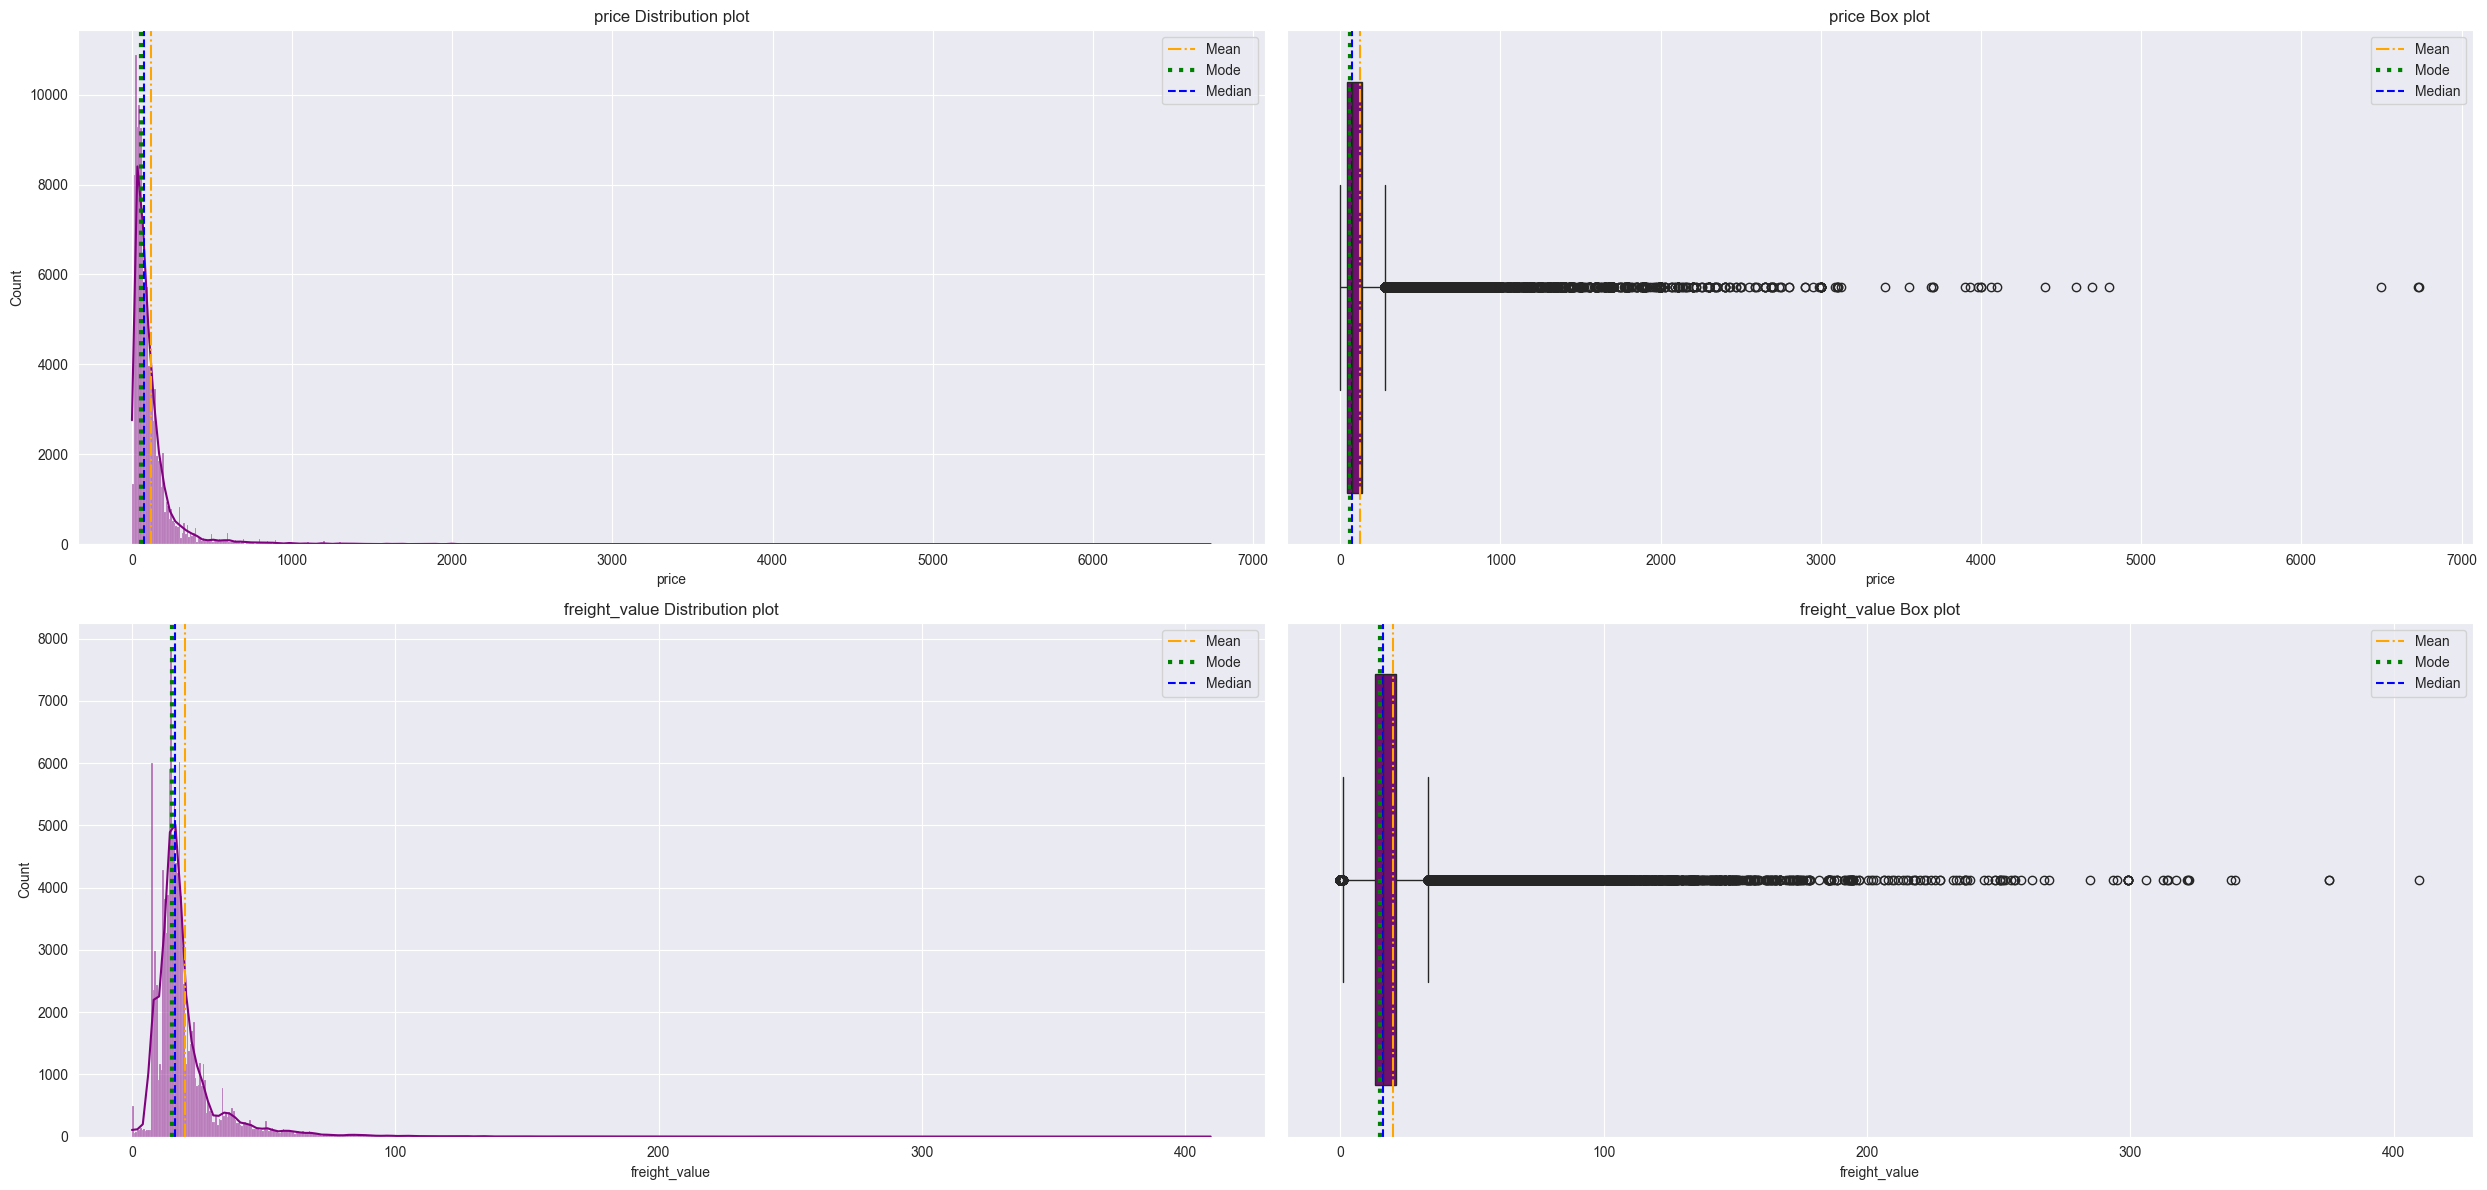

In [70]:
sns.set_style('darkgrid')
num_cols=['price','freight_value']
plt.figure(figsize=(25,12))
for i in range(len(num_cols)):
    plt.subplot(len(num_cols),2,2*i+1)
    sns.histplot(df[num_cols[i]],color='purple',kde=True)
    plt.axvline(df[num_cols[i]].mean(),label='Mean',linestyle='-.',color='orange')
    plt.axvline(df[num_cols[i]].mode()[0],label='Mode',linestyle=':',color='green',linewidth=3)
    plt.axvline(df[num_cols[i]].median(),label='Median',linestyle='--',color='blue')
    plt.legend()
    plt.title(f"{num_cols[i]} Distribution plot")

    plt.subplot(len(num_cols),2,2*i+2)
    sns.boxplot(data=df,x=num_cols[i],color='purple')
    plt.axvline(df[num_cols[i]].mean(),label='Mean',linestyle='-.',color='orange')
    plt.axvline(df[num_cols[i]].mode()[0],label='Mode',linestyle=':',color='green',linewidth=3)
    plt.axvline(df[num_cols[i]].median(),label='Median',linestyle='--',color='blue')
    plt.title(f"{num_cols[i]} Box plot")
    plt.legend()
plt.tight_layout()
plt.savefig('Order_item_price&Sprice_hisplot.png',dpi=500,bbox_inches="tight")
plt.show()

### insight
both price and freight price have outliers and are right skewed.

In [97]:
## most ordered product
x3=df[['product_id','order_item_id']]
x3

,product_id,order_item_id
0,4244733e06e7ecb4970a6e2683c13e61,1
1,e5f2d52b802189ee658865ca93d83a8f,1
2,c777355d18b72b67abbeef9df44fd0fd,1
3,7634da152a4610f1595efa32f14722fc,1
4,ac6c3623068f30de03045865e4e10089,1
...,...,...
112645,4aa6014eceb682077f9dc4bffebc05b0,1
112646,32e07fd915822b0765e448c4dd74c828,1
112647,72a30483855e2eafc67aee5dc2560482,1
112648,9c422a519119dcad7575db5af1ba540e,1


In [79]:
pr=pd.read_csv('../dataset/olist_products_dataset.csv')
pr=pr.iloc[:,:2]
pr.head(2)

,product_id,product_category_name
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria
1,3aa071139cb16b67ca9e5dea641aaa2f,artes


In [98]:
m1=pd.merge(left=x3,right=pr,left_on='product_id',right_on='product_id')
m1.head()

,product_id,order_item_id,product_category_name
0,4244733e06e7ecb4970a6e2683c13e61,1,cool_stuff
1,e5f2d52b802189ee658865ca93d83a8f,1,pet_shop
2,c777355d18b72b67abbeef9df44fd0fd,1,moveis_decoracao
3,7634da152a4610f1595efa32f14722fc,1,perfumaria
4,ac6c3623068f30de03045865e4e10089,1,ferramentas_jardim


In [82]:
prt=pd.read_csv('../dataset/product_category_name_translation.csv')
prt.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [102]:
m2=pd.merge(left=m1,right=prt,on='product_category_name')
m2

,product_id,order_item_id,product_category_name,product_category_name_english
0,4244733e06e7ecb4970a6e2683c13e61,1,cool_stuff,cool_stuff
1,e5f2d52b802189ee658865ca93d83a8f,1,pet_shop,pet_shop
2,c777355d18b72b67abbeef9df44fd0fd,1,moveis_decoracao,furniture_decor
3,7634da152a4610f1595efa32f14722fc,1,perfumaria,perfumery
4,ac6c3623068f30de03045865e4e10089,1,ferramentas_jardim,garden_tools
...,...,...,...,...
111018,4aa6014eceb682077f9dc4bffebc05b0,1,utilidades_domesticas,housewares
111019,32e07fd915822b0765e448c4dd74c828,1,informatica_acessorios,computers_accessories
111020,72a30483855e2eafc67aee5dc2560482,1,esporte_lazer,sports_leisure
111021,9c422a519119dcad7575db5af1ba540e,1,informatica_acessorios,computers_accessories


In [103]:
m2=m2.groupby('product_category_name_english')['order_item_id'].count().reset_index()
m2.columns=['Product Category','order count']
m2=m2.sort_values(by='order count',ascending=False)
m2.head()

,Product Category,order count
7,bed_bath_table,11115
43,health_beauty,9670
65,sports_leisure,8641
39,furniture_decor,8334
15,computers_accessories,7827


In [76]:
# Seller-wise Product Orders
x4=df.groupby('seller_id')['product_id'].count().reset_index()
x4.columns=['seller id','order count']
x4=x4.sort_values(by='order count',ascending=False)
x4

,seller id,order count
1235,6560211a19b47992c3666cc44a7e94c0,2033
881,4a3ca9315b744ce9f8e9374361493884,1987
368,1f50f920176fa81dab994f9023523100,1931
2481,cc419e0650a3c5ba77189a1882b7556a,1775
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551
...,...,...
1172,5f57db27027655e6c6a391601daa0258,1
1160,5e25c632f9db6cfb8bc100421c2737b6,1
1159,5e106d93b717c2682b9383da480364a1,1
2561,d36b07fd3c5088e477a72d1fccfe29d4,1


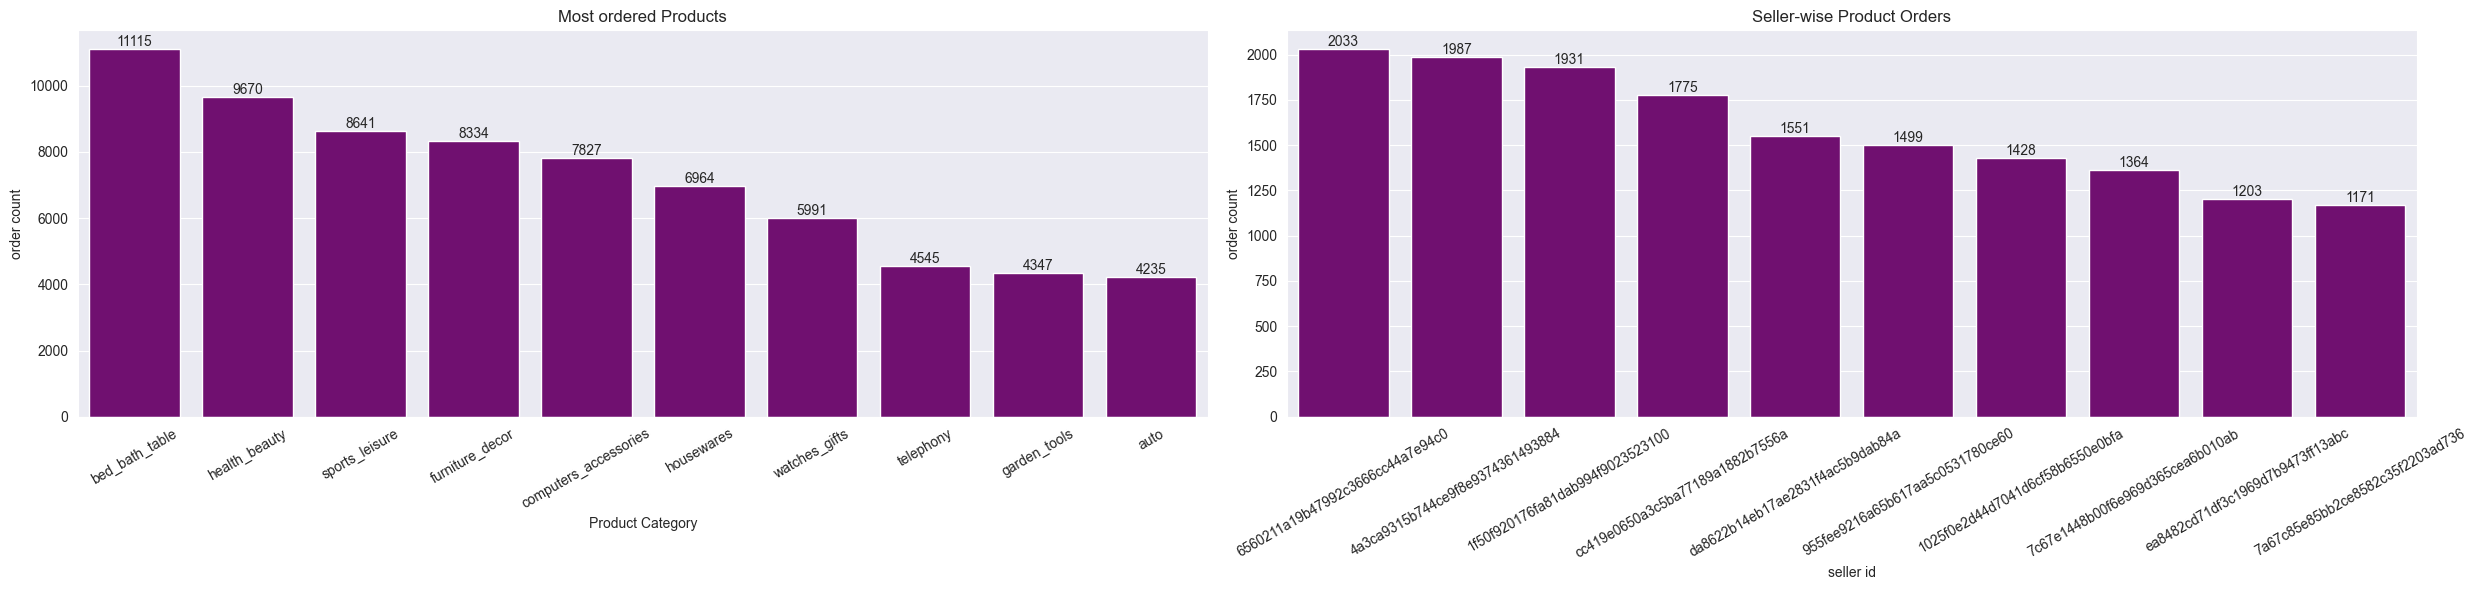

In [106]:
m2=m2.iloc[:10,:]
x4=x4.iloc[:10,:]

sns.set_style('darkgrid')

fig,ax= plt.subplots(1, 2, figsize=(25,6))

ax1=sns.barplot(m2,x='Product Category',y='order count', color="purple",ax=ax[0])
ax1.bar_label(ax1.containers[0])
ax1.set_title("Most ordered Products")
ax1.tick_params(axis='x', rotation=30)

ax2=sns.barplot(x4,x='seller id',y='order count', color="purple",ax=ax[1])
ax2.bar_label(ax2.containers[0])
ax2.set_title("Seller-wise Product Orders")
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('order_items_seller&product_insights.png',dpi=500,bbox_inches="tight")
plt.show()